In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
print("Pustaka klasifikasi kNN dan Naive Bayes berhasil dimuat.")

Pustaka klasifikasi kNN dan Naive Bayes berhasil dimuat.


In [2]:
# Memuat dataset ulasan dan aspek yang telah dibersihkan
path_reviews = '../outputs/reviews_preprocessed.csv'
if not os.path.exists(path_reviews):
    path_reviews = '../dataset/reviews.csv'
path_aspects = '../dataset/aspect_sentiments.csv'

df_reviews = pd.read_csv(path_reviews)
df_aspects = pd.read_csv(path_aspects)

if 'cleaned_text' not in df_reviews.columns:
    df_reviews['cleaned_text'] = df_reviews['text'].str.lower().str.replace(r'[^a-zA-Z\s]', ' ', regex=True).str.strip()

# Menggabungkan ulasan dengan label sentimen
df_data = pd.merge(df_aspects[['review_id', 'sentiment']], df_reviews[['id', 'cleaned_text']], left_on='review_id', right_on='id')
df_data = df_data[df_data['cleaned_text'].str.len() > 3].drop_duplicates(subset=['id', 'sentiment']).reset_index(drop=True)

X_text = df_data['cleaned_text']
y      = df_data['sentiment']

# Stratified split 80% train dan 20% test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Data Pelatihan : {len(X_train_raw):,} sampel")
print(f"Data Pengujian : {len(X_test_raw):,} sampel")
print("\nDistribusi Kelas pada Data Uji (%):")
print((y_test.value_counts(normalize=True)*100).round(2).to_dict())

Data Pelatihan : 5,296 sampel
Data Pengujian : 1,324 sampel

Distribusi Kelas pada Data Uji (%):
{'positive': 61.48, 'neutral': 33.69, 'negative': 4.83}


In [3]:
# 1. Bag-of-Words (CountVectorizer)
vec_bow = CountVectorizer(max_features=1000, ngram_range=(1, 2), min_df=3)
X_train_bow = vec_bow.fit_transform(X_train_raw)
X_test_bow  = vec_bow.transform(X_test_raw)

# 2. TF-IDF Vectorizer
vec_tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_train_tfidf = vec_tfidf.fit_transform(X_train_raw)
X_test_tfidf  = vec_tfidf.transform(X_test_raw)

print(f"Dimensi Matriks BoW   : {X_train_bow.shape}")
print(f"Dimensi Matriks TF-IDF: {X_train_tfidf.shape}")

Dimensi Matriks BoW   : (5296, 1000)
Dimensi Matriks TF-IDF: (5296, 1000)


In [4]:
# Menguji variasi nilai K = 1, 3, 5, 7, 9 pada fitur TF-IDF
k_candidates = [1, 3, 5, 7, 9]
knn_tuning_results = []

for k in k_candidates:
    knn = KNeighborsClassifier(n_neighbors=k, metric='cosine')
    knn.fit(X_train_tfidf, y_train)
    y_pred = knn.predict(X_test_tfidf)
    
    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
    knn_tuning_results.append({'K': k, 'Akurasi': round(acc, 4), 'Macro_F1': round(f1_macro, 4)})

df_knn_tune = pd.DataFrame(knn_tuning_results)
print("=== HASIL PENYETELAN NILAI K PADA kNN (FITUR TF-IDF) ===")
print(df_knn_tune.to_string(index=False))

best_k = df_knn_tune.sort_values(by='Macro_F1', ascending=False).iloc[0]['K']
print(f"\nNilai K Terbaik Berdasarkan Macro F1: K = {int(best_k)}")

=== HASIL PENYETELAN NILAI K PADA kNN (FITUR TF-IDF) ===
 K  Akurasi  Macro_F1
 1   0.5823    0.4542
 3   0.6231    0.4985
 5   0.6745    0.5246
 7   0.6828    0.5232
 9   0.6956    0.5355

Nilai K Terbaik Berdasarkan Macro F1: K = 9


In [5]:
# Melatih model-model pembanding
model_mnb_bow   = MultinomialNB(alpha=1.0)
model_mnb_tfidf = MultinomialNB(alpha=1.0)
model_best_knn  = KNeighborsClassifier(n_neighbors=int(best_k), metric='cosine')

model_mnb_bow.fit(X_train_bow, y_train)
model_mnb_tfidf.fit(X_train_tfidf, y_train)
model_best_knn.fit(X_train_tfidf, y_train)

# Prediksi data uji
pred_mnb_bow   = model_mnb_bow.predict(X_test_bow)
pred_mnb_tfidf = model_mnb_tfidf.predict(X_test_tfidf)
pred_knn       = model_best_knn.predict(X_test_tfidf)

# Komparasi Metrik Evaluasi
def ringkas_evaluasi(y_true, y_pred, nama):
    return {
        'Model & Fitur': nama,
        'Akurasi': round(accuracy_score(y_true, y_pred), 4),
        'Precision (Macro)': round(precision_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'Recall (Macro)': round(recall_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'F1-Score (Macro)': round(f1_score(y_true, y_pred, average='macro', zero_division=0), 4)
    }

hasil_klasifikasi = [
    ringkas_evaluasi(y_test, pred_mnb_bow, 'MultinomialNB (Bag-of-Words)'),
    ringkas_evaluasi(y_test, pred_mnb_tfidf, 'MultinomialNB (TF-IDF)'),
    ringkas_evaluasi(y_test, pred_knn, f'kNN (K={int(best_k)}, Cosine TF-IDF)')
]

df_hasil_klasifikasi = pd.DataFrame(hasil_klasifikasi)
print("=== TABEL KOMPARASI KLASIFIKASI SENTIMEN JS9 ===")
print(df_hasil_klasifikasi.to_string(index=False))

=== TABEL KOMPARASI KLASIFIKASI SENTIMEN JS9 ===
               Model & Fitur  Akurasi  Precision (Macro)  Recall (Macro)  F1-Score (Macro)
MultinomialNB (Bag-of-Words)   0.6926             0.5626          0.5992            0.5492
      MultinomialNB (TF-IDF)   0.7092             0.4559          0.4551            0.4487
    kNN (K=9, Cosine TF-IDF)   0.6956             0.6264          0.5087            0.5355



Classification Report: MultinomialNB (TF-IDF):
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00        64
     neutral       0.63      0.47      0.54       446
    positive       0.73      0.90      0.81       814

    accuracy                           0.71      1324
   macro avg       0.46      0.46      0.45      1324
weighted avg       0.66      0.71      0.68      1324



<string>:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown



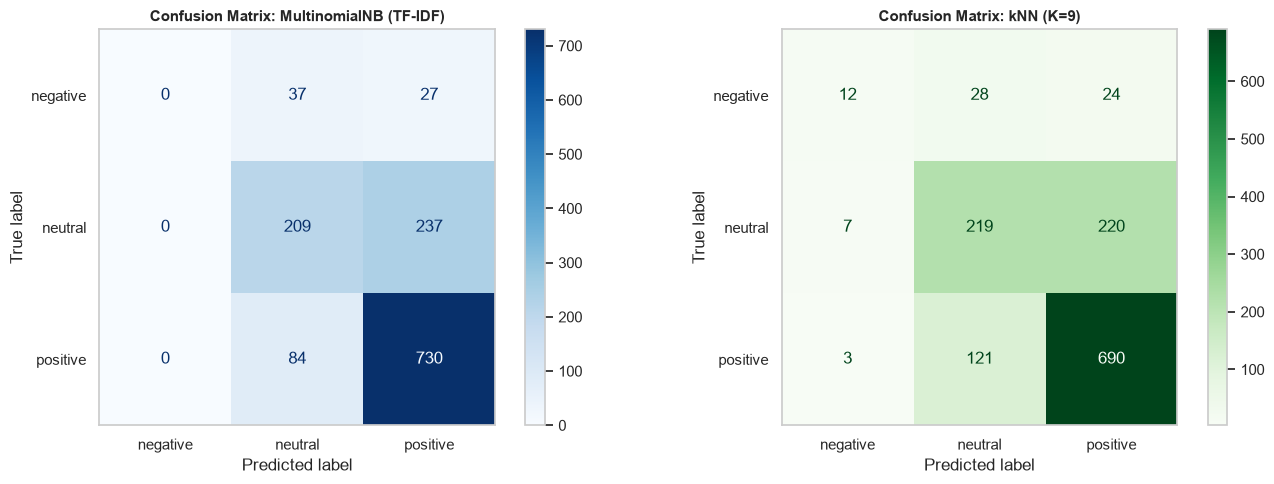

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
classes = sorted(y.unique())

# Confusion Matrix MultinomialNB TF-IDF
cm_mnb = confusion_matrix(y_test, pred_mnb_tfidf, labels=classes)
disp_mnb = ConfusionMatrixDisplay(confusion_matrix=cm_mnb, display_labels=classes)
disp_mnb.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Confusion Matrix: MultinomialNB (TF-IDF)', fontsize=11, fontweight='bold')
axes[0].grid(False)

# Confusion Matrix kNN
cm_knn = confusion_matrix(y_test, pred_knn, labels=classes)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=classes)
disp_knn.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title(f'Confusion Matrix: kNN (K={int(best_k)})', fontsize=11, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

print("\nClassification Report: MultinomialNB (TF-IDF):")
print(classification_report(y_test, pred_mnb_tfidf, zero_division=0))

In [7]:
import joblib

os.makedirs('../outputs', exist_ok=True)
path_saved_model = '../outputs/naive_bayes_sentiment_js9.joblib'
joblib.dump({'model': model_mnb_tfidf, 'vectorizer': vec_tfidf}, path_saved_model)
df_hasil_klasifikasi.to_csv('../outputs/evaluasi_klasifikasi_js9.csv', index=False)
print(f"Model Naive Bayes dan Vectorizer tersimpan ke: {path_saved_model}")

Model Naive Bayes dan Vectorizer tersimpan ke: ../outputs/naive_bayes_sentiment_js9.joblib
